# Scratch CNN: Obadah Ghizawi


In [46]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import json
import random
import time
from driver_dataset import DriverDataset

root = Path.cwd()
df = pd.read_csv(root / "driver_imgs_list.csv")
SEED = 42
CLASSES = [f"c{i}" for i in range(10)]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
MAX_EPOCHS = 40
PATIENCE = 10
print("Device:", DEVICE)

Device: cuda


## Fixed splits


In [47]:
split_root = root / "data" / "splits"
split_files = [split_root / protocol / f"{part}.csv"
               for protocol in ["driver_based", "random"]
               for part in ["train", "val", "test"]]
if any(p.exists() for p in split_files) and not all(p.exists() for p in split_files):
    raise ValueError("Incomplete split files: restore all six manifests before continuing.")
if not any(p.exists() for p in split_files):
    rng = np.random.default_rng(SEED)
    drivers = rng.permutation(sorted(df.subject.unique()))
    groups = {"train": drivers[:18], "val": drivers[18:22], "test": drivers[22:]}
    for part, subjects in groups.items():
        folder = split_root / "driver_based"
        folder.mkdir(parents=True, exist_ok=True)
        df[df.subject.isin(subjects)].to_csv(folder / f"{part}.csv", index=False)
    pieces = {part: [] for part in groups}
    for _, group in df.groupby("classname"):
        group = group.iloc[rng.permutation(len(group))]
        a, b = int(len(group) * .70), int(len(group) * .85)
        for part, rows in zip(pieces, [group.iloc[:a], group.iloc[a:b], group.iloc[b:]]):
            pieces[part].append(rows)
    folder = split_root / "random"
    folder.mkdir(parents=True, exist_ok=True)
    for part, rows in pieces.items():
        pd.concat(rows).to_csv(folder / f"{part}.csv", index=False)

splits = {}
for protocol in ["driver_based", "random"]:
    splits[protocol] = {part: pd.read_csv(split_root / protocol / f"{part}.csv")
                        for part in ["train", "val", "test"]}
    frames = splits[protocol]
    images = pd.concat(frames.values())["img"]
    if images.duplicated().any():
        raise ValueError(f"Duplicate images across {protocol} partitions.")
    if protocol == "driver_based":
        subjects = [set(frame.subject) for frame in frames.values()]
        if any(subjects[i] & subjects[j] for i, j in [(0, 1), (0, 2), (1, 2)]):
            raise ValueError("Driver-based partitions contain overlapping drivers.")
    print(protocol, {part: (len(frame), frame.subject.nunique())
                     for part, frame in frames.items()})

driver_based {'train': (15732, 18), 'val': (3603, 4), 'test': (3089, 4)}
random {'train': (15692, 26), 'val': (3364, 26), 'test': (3368, 26)}


## Preprocessing and model


In [48]:
def transform(augment=False):
    steps = [T.Resize((192, 256))]
    if augment:
        steps += [T.RandomRotation(8), T.ColorJitter(brightness=.15, contrast=.15)]
    return T.Compose(steps + [T.ToTensor(), T.Normalize((.5,) * 3, (.5,) * 3)])

def loader(frame, augment=False, shuffle=False):
    dataset = DriverDataset(frame, root / "imgs" / "train", transform(augment))
    # Zero workers keeps notebook execution straightforward on Windows.
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        return self.block(x)


class DriverCNN(nn.Module):
    """Three convolution blocks and a small spatial max-pooling head."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
        )
        self.classifier = nn.Sequential(
            # Retain a coarse spatial grid instead of one value per channel.
            nn.AdaptiveMaxPool2d((3, 4)),
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128 * 3 * 4, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

## Metrics and training


In [49]:
def metrics(truth, predictions):
    matrix = np.zeros((10, 10), dtype=int)
    np.add.at(matrix, (truth, predictions), 1)
    correct = matrix.diagonal()
    support = matrix.sum(axis=1)
    precision = np.divide(correct, matrix.sum(axis=0), out=np.zeros(10), where=matrix.sum(axis=0) != 0)
    recall = np.divide(correct, support, out=np.zeros(10), where=support != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(10), where=precision + recall != 0)
    report = pd.DataFrame({"class": CLASSES, "precision": precision,
                           "recall": recall, "f1": f1, "support": support})
    return {"accuracy": float(correct.sum() / matrix.sum()), "macro_f1": float(f1.mean())}, report, matrix

def epoch(model, batches, optimizer=None):
    model.train(optimizer is not None)
    total_loss, truth, predictions = 0., [], []
    with torch.set_grad_enabled(optimizer is not None):
        for images, labels in batches:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)
            if optimizer is not None:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            truth.extend(labels.cpu().tolist())
            predictions.extend(logits.detach().argmax(1).cpu().tolist())
    scores, report, matrix = metrics(truth, predictions)
    scores["loss"] = total_loss / len(truth)
    return scores, report, matrix, predictions

HARDWARE = torch.cuda.get_device_name() if DEVICE.type == "cuda" else "CPU"
def train_run(protocol, augment):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    folder = root / "results" / "scratch_cnn" / f"{protocol}_aug_{augment}"
    folder.mkdir(parents=True, exist_ok=True)
    config = dict(protocol=protocol, augmentation=augment, seed=SEED,
                  image_size=[192, 256], batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS,
                  patience=PATIENCE, lr=1e-4, weight_decay=1e-4,
                  selection="validation macro-F1", hardware=HARDWARE,
                  normalization_mean=[.5]*3, normalization_std=[.5]*3)
    if (folder / "best.pt").exists():
        print("Reusing saved run:", folder.name)
        return folder
    train_batches = loader(splits[protocol]["train"], augment, shuffle=True)
    val_batches = loader(splits[protocol]["val"])
    model = DriverCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
    history, best, stale = [], -1., 0
    start = time.perf_counter()
    for number in range(1, MAX_EPOCHS + 1):
        train_scores, _, _, _ = epoch(model, train_batches, optimizer)
        val_scores, _, _, _ = epoch(model, val_batches)
        history.append({"epoch": number, **{f"train_{k}": v for k, v in train_scores.items()},
                        **{f"val_{k}": v for k, v in val_scores.items()}})
        print(folder.name, number, "val F1:", round(val_scores["macro_f1"], 4), flush=True)
        if val_scores["macro_f1"] > best:
            best, stale = val_scores["macro_f1"], 0
            torch.save(model.state_dict(), folder / "best.pt")
            config["best_epoch"] = number
        else:
            stale += 1
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
        config["hours"] = (time.perf_counter() - start) / 3600
        (folder / "config.json").write_text(json.dumps(config, indent=2))
        if stale >= PATIENCE:
            break
    return folder

## Run the experiments


In [5]:
runs = {
    "driver_on": train_run("driver_based", True),
    "driver_off": train_run("driver_based", False),
    "random_on": train_run("random", True),
}

driver_based_aug_True 1 val F1: 0.4117
driver_based_aug_True 2 val F1: 0.5395
driver_based_aug_True 3 val F1: 0.5785
driver_based_aug_True 4 val F1: 0.5894
driver_based_aug_True 5 val F1: 0.6039
driver_based_aug_True 6 val F1: 0.6745
driver_based_aug_True 7 val F1: 0.6913
driver_based_aug_True 8 val F1: 0.7157
driver_based_aug_True 9 val F1: 0.711
driver_based_aug_True 10 val F1: 0.693
driver_based_aug_True 11 val F1: 0.7262
driver_based_aug_True 12 val F1: 0.7101
driver_based_aug_True 13 val F1: 0.7241
driver_based_aug_True 14 val F1: 0.6934
driver_based_aug_True 15 val F1: 0.7284
driver_based_aug_True 16 val F1: 0.7384
driver_based_aug_True 17 val F1: 0.7358
driver_based_aug_True 18 val F1: 0.7487
driver_based_aug_True 19 val F1: 0.755
driver_based_aug_True 20 val F1: 0.7351
driver_based_aug_True 21 val F1: 0.7504
driver_based_aug_True 22 val F1: 0.7566
driver_based_aug_True 23 val F1: 0.7587
driver_based_aug_True 24 val F1: 0.7475
driver_based_aug_True 25 val F1: 0.7379
driver_based

## Validation results, curves, and ablation


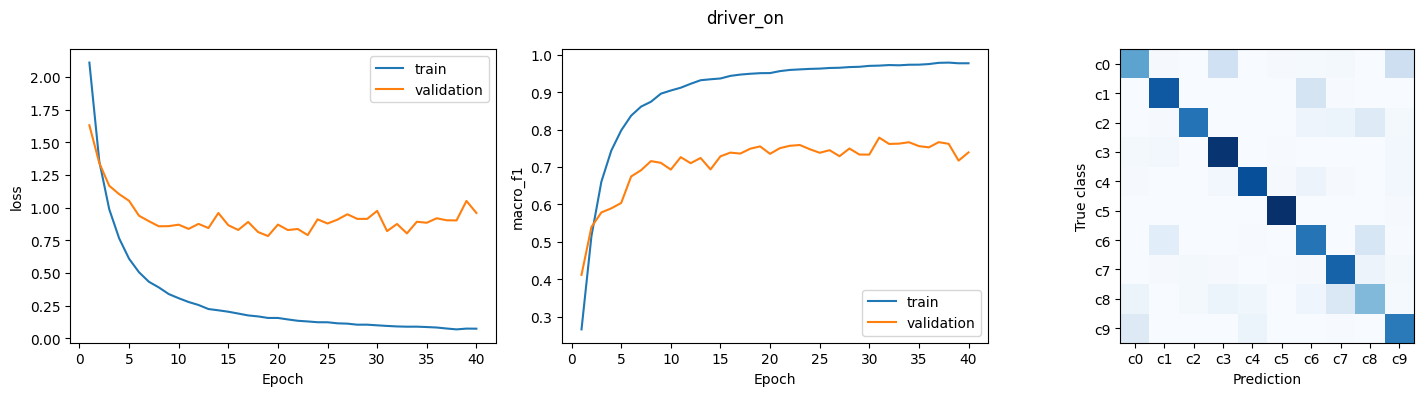

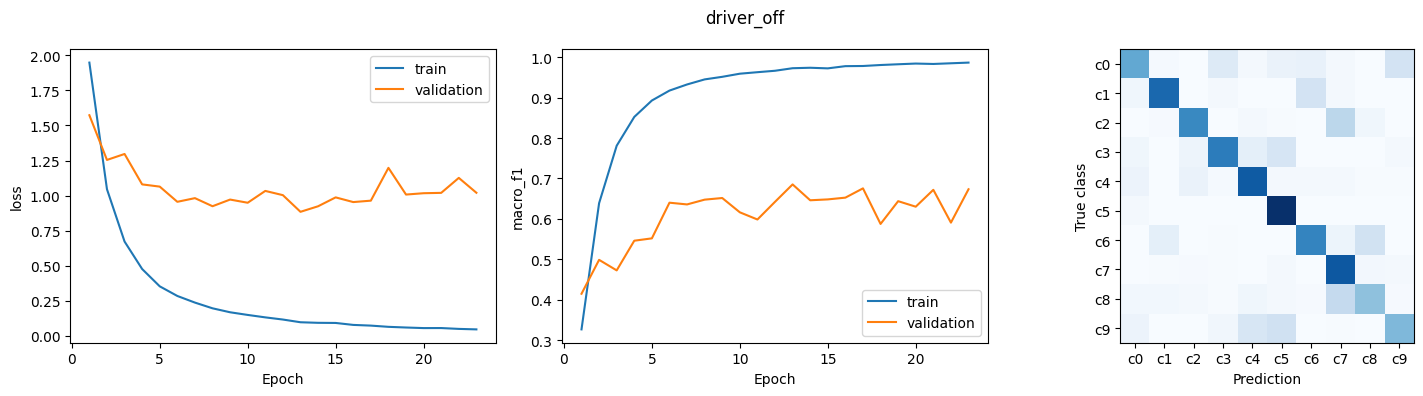

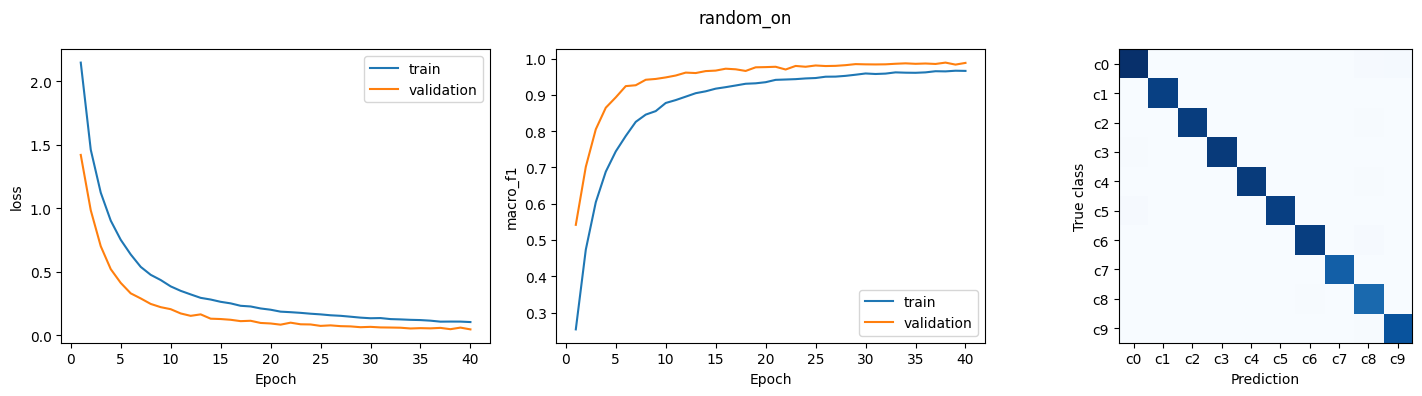

,run,accuracy,macro_f1,loss,train_macro_f1,f1_gap
0,driver_on,0.785457,0.778385,0.820202,0.993935,0.215550
1,driver_off,0.695532,0.685232,0.884831,0.994975,0.309743
2,random_on,0.989001,0.988811,0.049611,0.995371,0.006560


,class,precision_on,recall_on,f1_on,support_on,precision_off,recall_off,f1_off,support_off
0,c0,0.717857,0.540323,0.616564,372,0.689531,0.513441,0.588598,372
1,c1,0.833333,0.822281,0.827770,377,0.835777,0.755968,0.793872,377
2,c2,0.951049,0.741144,0.833078,367,0.815700,0.651226,0.724242,367
3,c3,0.768085,0.918575,0.836616,393,0.771772,0.653944,0.707989,393
4,c4,0.900000,0.857143,0.878049,378,0.711268,0.801587,0.753731,378
5,c5,0.968421,0.989247,0.978723,372,0.671587,0.978495,0.796499,372
6,c6,0.679198,0.728495,0.702983,372,0.694051,0.658602,0.675862,372
7,c7,0.774869,0.865497,0.817680,342,0.570370,0.900585,0.698413,342
8,c8,0.567474,0.550336,0.558773,298,0.609756,0.503356,0.551471,298
9,c9,0.683117,0.792169,0.733612,332,0.650794,0.493976,0.561644,332


In [6]:
def load_model(folder):
    model = DriverCNN().to(DEVICE)
    model.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
    return model

def evaluate(model, frame, folder, name):
    scores, report, matrix, predictions = epoch(model, loader(frame))
    report.to_csv(folder / f"{name}_classes.csv", index=False)
    output = frame[["img", "subject", "classname"]].copy()
    output.columns = ["image_id", "subject", "true_class"]
    output["true_label"] = frame.classname.str[1:].astype(int).to_numpy()
    output["predicted_label"] = predictions
    output.to_csv(folder / f"{name}_predictions.csv", index=False)
    (folder / f"{name}_metrics.json").write_text(json.dumps(scores, indent=2))
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(folder / f"{name}_confusion.csv")
    return scores, output, matrix

summary = []
for name, folder in runs.items():
    config = json.loads((folder / "config.json").read_text())
    protocol = config["protocol"]
    model = load_model(folder)
    val, predictions, matrix = evaluate(model, splits[protocol]["val"], folder, "validation")
    train, _, _ = evaluate(model, splits[protocol]["train"], folder, "train_clean")
    summary.append(dict(run=name, **val, train_macro_f1=train["macro_f1"],
                        f1_gap=train["macro_f1"] - val["macro_f1"]))
    history = pd.read_csv(folder / "history.csv")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes[:2], ["loss", "macro_f1"]):
        ax.plot(history.epoch, history[f"train_{metric}"], label="train")
        ax.plot(history.epoch, history[f"val_{metric}"], label="validation")
        ax.set(xlabel="Epoch", ylabel=metric)
        ax.legend()
    axes[2].imshow(matrix, cmap="Blues")
    axes[2].set(xticks=range(10), yticks=range(10), xticklabels=CLASSES,
                yticklabels=CLASSES, xlabel="Prediction", ylabel="True class")
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(folder / "curves_confusion.png")
    plt.show()
summary = pd.DataFrame(summary)
summary.to_csv(root / "results" / "scratch_cnn" / "comparison.csv", index=False)
display(summary)
display(pd.read_csv(runs["driver_on"] / "validation_classes.csv").merge(
    pd.read_csv(runs["driver_off"] / "validation_classes.csv"), on="class", suffixes=("_on", "_off")))

## Robustness by unseen driver and failure images


,subject,images,accuracy,macro_f1
0,p014,876,0.716895,0.605602
1,p016,1078,0.937848,0.932309
2,p047,835,0.810778,0.773362
3,p075,814,0.631450,0.566782


true_class,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
subject,,,,,,,,,,
p014,100,103,100,100,103,102,101,77,38,52
p016,111,102,101,128,104,104,108,101,99,120
p047,80,91,81,86,82,87,81,82,82,83
p075,81,81,85,79,89,79,82,82,79,77


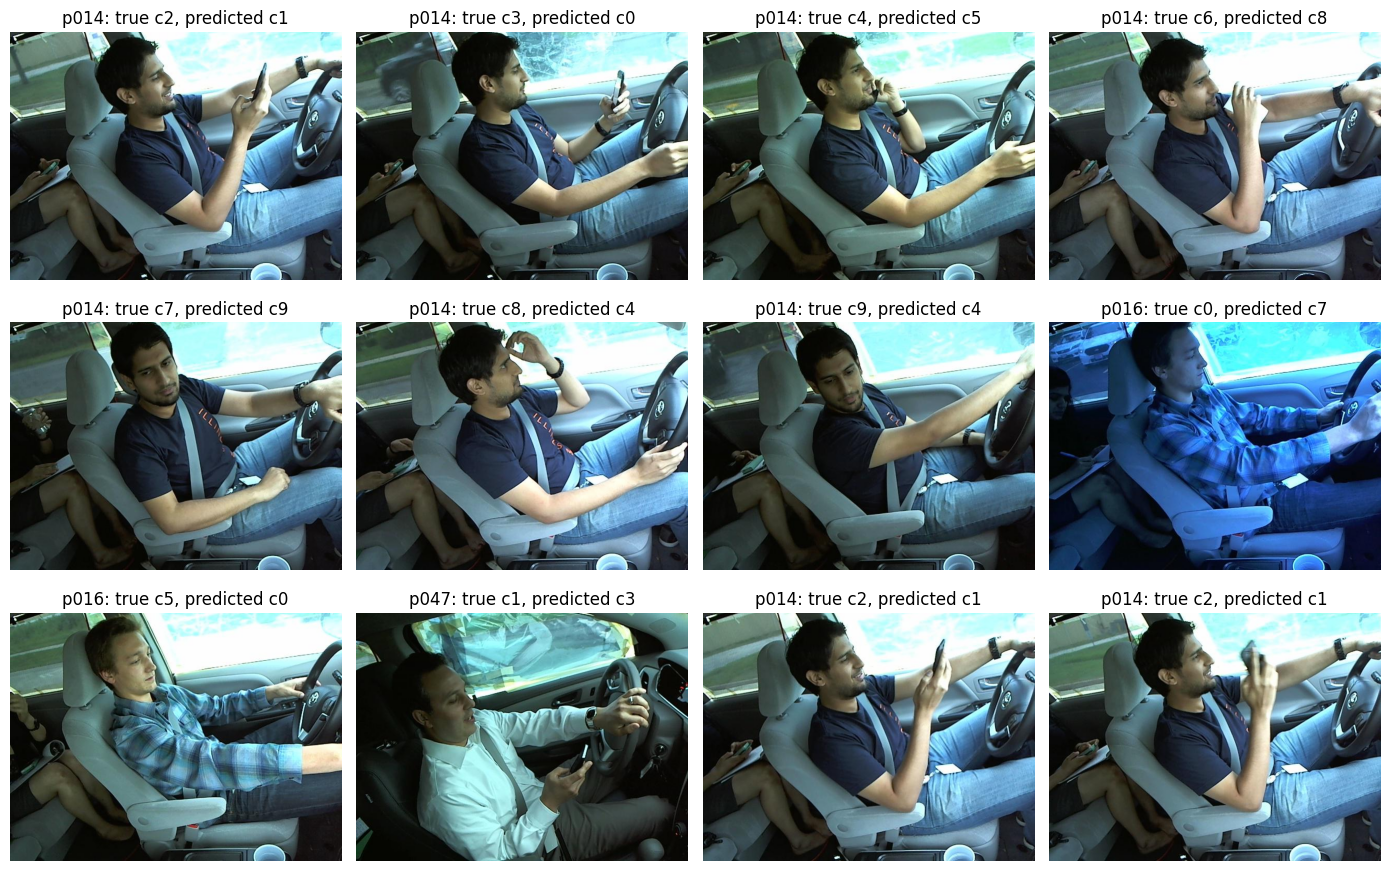

In [7]:
folder = runs["driver_on"]
predictions = pd.read_csv(folder / "validation_predictions.csv")
driver_results = []
for subject, group in predictions.groupby("subject"):
    scores, _, _ = metrics(group.true_label.to_numpy(), group.predicted_label.to_numpy())
    driver_results.append(dict(subject=subject, images=len(group), **scores))
driver_results = pd.DataFrame(driver_results)
driver_results.to_csv(folder / "unseen_drivers.csv", index=False)
display(driver_results)
display(pd.crosstab(predictions.subject, predictions.true_class))
errors = predictions[predictions.true_label != predictions.predicted_label]
# Spread examples across true classes rather than showing only the most common class.
examples = errors.groupby("true_class", group_keys=False).head(1)
examples = pd.concat([examples, errors.drop(examples.index)]).head(12)
examples = examples.copy()
examples["possible_cause"] = ""  # Fill in after inspecting each actual image.
examples.to_csv(folder / "failure_analysis.csv", index=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    with Image.open(root / "imgs" / "train" / row.true_class / row.image_id) as image:
        ax.imshow(image)
    ax.set_title(f"{row.subject}: true {row.true_class}, predicted c{row.predicted_label}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Written interpretation — complete after running
## Final test release


In [8]:
RUN_FINAL_TEST = False
SELECTED_AUGMENTATION = True  # Set from the driver-based validation ablation before release.
if RUN_FINAL_TEST:
    for protocol in ["driver_based", "random"]:
        folder = root / "results" / "scratch_cnn" / f"{protocol}_aug_{SELECTED_AUGMENTATION}"
        if not (folder / "best.pt").exists():
            raise ValueError("Train the selected configuration for both protocols before testing.")
    for protocol in ["driver_based", "random"]:
        folder = root / "results" / "scratch_cnn" / f"{protocol}_aug_{SELECTED_AUGMENTATION}"
        marker = folder / "test_started.txt"
        if marker.exists():
            raise RuntimeError("Test evaluation was already started; inspect saved results rather than rerunning.")
        marker.write_text("Final evaluation started. Document failures before considering any rerun.")
        evaluate(load_model(folder), splits[protocol]["test"], folder, "test")

## Custom residual CNN

In [50]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.skip = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.skip = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.layers(x) + self.skip(x))


class ResidualDriverCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            ResidualBlock(32, 32),
            ResidualBlock(32, 64, stride=2),
            ResidualBlock(64, 64),
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 128),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveMaxPool2d((3, 4)),
            nn.Flatten(),
            nn.Dropout(.3),
            nn.Linear(128 * 3 * 4, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print("Trainable parameters:", sum(p.numel() for p in ResidualDriverCNN().parameters()))

Trainable parameters: 692138


## Residual CNN training

In [51]:
def train_residual_run(protocol, augment):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    folder = root / "results" / "residual_cnn" / f"{protocol}_aug_{augment}"
    folder.mkdir(parents=True, exist_ok=True)
    config = dict(architecture="custom_11_conv_5_residual_blocks", protocol=protocol, augmentation=augment, seed=SEED,
                  image_size=[192, 256], batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS,
                  patience=PATIENCE, lr=1e-4, weight_decay=1e-4,
                  selection="validation macro-F1", hardware=HARDWARE,
                  normalization_mean=[.5]*3, normalization_std=[.5]*3)
    if (folder / "best.pt").exists():
        print("Reusing saved run:", folder.name)
        return folder
    train_batches = loader(splits[protocol]["train"], augment, shuffle=True)
    val_batches = loader(splits[protocol]["val"])
    model = ResidualDriverCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
    history, best, stale = [], -1., 0
    start = time.perf_counter()
    for number in range(1, MAX_EPOCHS + 1):
        train_scores, _, _, _ = epoch(model, train_batches, optimizer)
        val_scores, _, _, _ = epoch(model, val_batches)
        history.append({"epoch": number, **{f"train_{k}": v for k, v in train_scores.items()},
                        **{f"val_{k}": v for k, v in val_scores.items()}})
        print(folder.name, number, "val F1:", round(val_scores["macro_f1"], 4), flush=True)
        if val_scores["macro_f1"] > best:
            best, stale = val_scores["macro_f1"], 0
            torch.save(model.state_dict(), folder / "best.pt")
            config["best_epoch"] = number
        else:
            stale += 1
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
        config["hours"] = (time.perf_counter() - start) / 3600
        (folder / "config.json").write_text(json.dumps(config, indent=2))
        if stale >= PATIENCE:
            break
    return folder

## Residual CNN experiments

In [11]:
residual_runs = {
    "driver_on": train_residual_run("driver_based", True),
    "random_on": train_residual_run("random", True),
}

driver_based_aug_True 1 val F1: 0.4688
driver_based_aug_True 2 val F1: 0.6139
driver_based_aug_True 3 val F1: 0.6362
driver_based_aug_True 4 val F1: 0.6697
driver_based_aug_True 5 val F1: 0.6462
driver_based_aug_True 6 val F1: 0.7154
driver_based_aug_True 7 val F1: 0.7152
driver_based_aug_True 8 val F1: 0.6934
driver_based_aug_True 9 val F1: 0.6942
driver_based_aug_True 10 val F1: 0.7354
driver_based_aug_True 11 val F1: 0.6937
driver_based_aug_True 12 val F1: 0.746
driver_based_aug_True 13 val F1: 0.7158
driver_based_aug_True 14 val F1: 0.6596
driver_based_aug_True 15 val F1: 0.7204
driver_based_aug_True 16 val F1: 0.747
driver_based_aug_True 17 val F1: 0.6649
driver_based_aug_True 18 val F1: 0.7308
driver_based_aug_True 19 val F1: 0.7518
driver_based_aug_True 20 val F1: 0.7703
driver_based_aug_True 21 val F1: 0.7564
driver_based_aug_True 22 val F1: 0.7421
driver_based_aug_True 23 val F1: 0.7404
driver_based_aug_True 24 val F1: 0.7368
driver_based_aug_True 25 val F1: 0.7003
driver_base

## Residual CNN validation and comparison

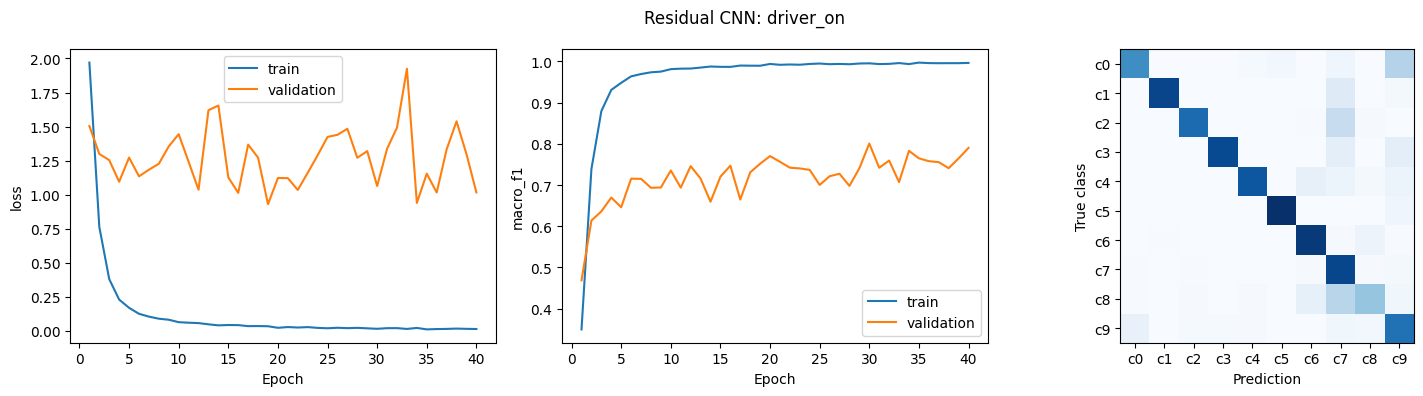

,subject,images,accuracy,macro_f1
0,p014,876,0.816210,0.780410
1,p016,1078,0.906308,0.896281
2,p047,835,0.873054,0.843159
3,p075,814,0.576167,0.531262


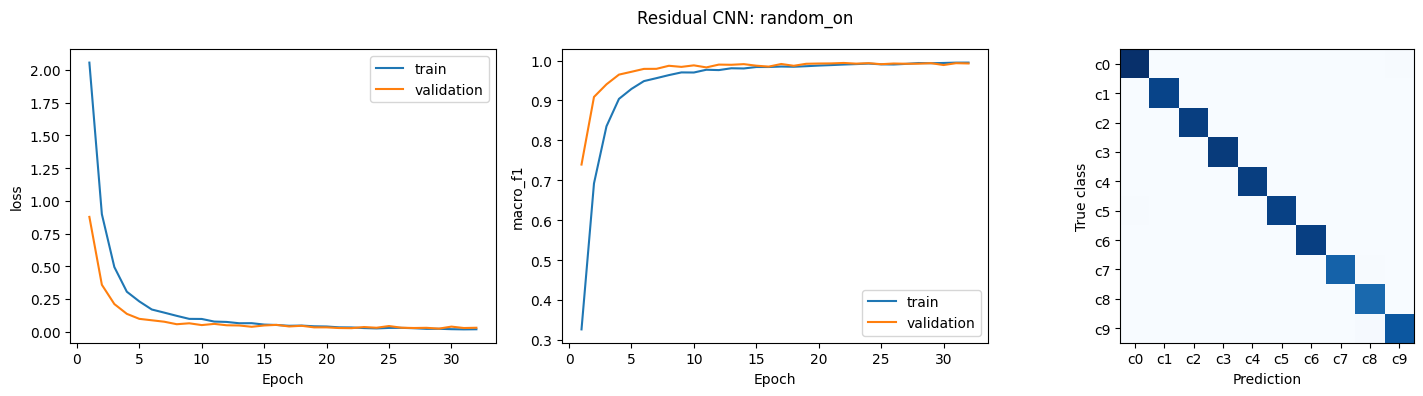

,run,accuracy,macro_f1,loss,train_macro_f1,f1_gap,model
0,driver_on,0.785457,0.778385,0.820202,0.993935,0.215550,original
1,driver_off,0.695532,0.685232,0.884831,0.994975,0.309743,original
2,random_on,0.989001,0.988811,0.049611,0.995371,0.006560,original
3,driver_on,0.802109,0.800785,1.062932,0.998990,0.198205,residual
4,random_on,0.994055,0.993885,0.026766,0.998861,0.004976,residual


In [12]:
residual_summary = []
for name, folder in residual_runs.items():
    protocol = json.loads((folder / "config.json").read_text())["protocol"]
    residual_model = ResidualDriverCNN().to(DEVICE)
    residual_model.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
    scores, predictions, matrix = evaluate(residual_model, splits[protocol]["val"], folder, "validation")
    train_scores, _, _ = evaluate(residual_model, splits[protocol]["train"], folder, "train_clean")
    residual_summary.append(dict(run=name, **scores, train_macro_f1=train_scores["macro_f1"],
                                 f1_gap=train_scores["macro_f1"] - scores["macro_f1"]))
    history = pd.read_csv(folder / "history.csv")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes[:2], ["loss", "macro_f1"]):
        ax.plot(history.epoch, history[f"train_{metric}"], label="train")
        ax.plot(history.epoch, history[f"val_{metric}"], label="validation")
        ax.set(xlabel="Epoch", ylabel=metric)
        ax.legend()
    axes[2].imshow(matrix, cmap="Blues")
    axes[2].set(xticks=range(10), yticks=range(10), xticklabels=CLASSES,
                yticklabels=CLASSES, xlabel="Prediction", ylabel="True class")
    fig.suptitle(f"Residual CNN: {name}")
    fig.tight_layout()
    fig.savefig(folder / "curves_confusion.png")
    plt.show()
    if protocol == "driver_based":
        driver_scores = []
        for subject, group in predictions.groupby("subject"):
            values, _, _ = metrics(group.true_label.to_numpy(), group.predicted_label.to_numpy())
            driver_scores.append(dict(subject=subject, images=len(group), **values))
        pd.DataFrame(driver_scores).to_csv(folder / "unseen_drivers.csv", index=False)
        display(pd.DataFrame(driver_scores))

residual_summary = pd.DataFrame(residual_summary)
residual_summary.to_csv(root / "results" / "residual_cnn" / "comparison.csv", index=False)
original_summary = pd.read_csv(root / "results" / "scratch_cnn" / "comparison.csv")
display(pd.concat([original_summary.assign(model="original"),
                   residual_summary.assign(model="residual")], ignore_index=True))

## Pretrained ResNet18 and preprocessing

In [52]:
from torchvision.models import resnet18, ResNet18_Weights

RESNET_WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
resnet_preprocess = RESNET_WEIGHTS.transforms()

def resnet_loader(frame, training=False):
    steps = []
    if training:
        steps = [T.RandomRotation(8), T.ColorJitter(brightness=.15, contrast=.15)]
    dataset = DriverDataset(frame, root / "imgs" / "train",
                            T.Compose(steps + [resnet_preprocess]))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=training, num_workers=0)


def make_resnet18(pretrained=False):
    network = resnet18(weights=RESNET_WEIGHTS if pretrained else None)
    network.fc = nn.Linear(network.fc.in_features, 10)
    return network.to(DEVICE)

## ResNet18 head training and fine-tuning

In [53]:
def train_resnet18(protocol):
    folder = root / "results" / "pretrained_resnet18" / protocol
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / "complete.json").exists():
        print("Reusing completed ResNet18 run:", protocol)
        return folder
    if (folder / "best.pt").exists():
        raise RuntimeError("Incomplete ResNet18 run. Use a new results folder for a fresh run.")
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    network = make_resnet18(pretrained=True)
    train_batches = resnet_loader(splits[protocol]["train"], training=True)
    val_batches = resnet_loader(splits[protocol]["val"])
    config = dict(architecture="torchvision ResNet18", weights=str(RESNET_WEIGHTS),
                  protocol=protocol, seed=SEED, hardware=HARDWARE, batch_size=BATCH_SIZE,
                  head_epochs=3, head_lr=.001, backbone_lr=.00001, finetune_head_lr=.0001,
                  weight_decay=.0001, max_finetune_epochs=MAX_EPOCHS, patience=PATIENCE,
                  selection="validation macro-F1", preprocessing=str(resnet_preprocess),
                  augmentation="rotation 8 degrees, brightness/contrast 0.15, training only")
    # Keep frozen backbone BatchNorm statistics fixed during head training.
    def freeze_backbone_stats(module, inputs):
        for name, child in module.named_children():
            if name != "fc":
                child.eval()
    for parameter in network.parameters():
        parameter.requires_grad = False
    for parameter in network.fc.parameters():
        parameter.requires_grad = True
    hook = network.register_forward_pre_hook(freeze_backbone_stats)
    optimizer = torch.optim.Adam(network.fc.parameters(), lr=.001, weight_decay=.0001)
    history, best, stale = [], -1., 0
    start = time.perf_counter()
    for number in range(1, 3 + MAX_EPOCHS + 1):
        if number == 4:
            hook.remove()
            for parameter in network.parameters():
                parameter.requires_grad = True
            optimizer = torch.optim.Adam([
                {"params": [p for name, p in network.named_parameters() if not name.startswith("fc.")], "lr": .00001},
                {"params": network.fc.parameters(), "lr": .0001},
            ], weight_decay=.0001)
            stale = 0
        stage = "head" if number <= 3 else "fine_tune"
        train_scores, _, _, _ = epoch(network, train_batches, optimizer)
        val_scores, _, _, _ = epoch(network, val_batches)
        history.append(dict(epoch=number, stage=stage,
                            **{f"train_{k}": v for k, v in train_scores.items()},
                            **{f"val_{k}": v for k, v in val_scores.items()}))
        print("ResNet18", protocol, number, stage, "val F1:", round(val_scores["macro_f1"], 4), flush=True)
        if val_scores["macro_f1"] > best:
            best, stale = val_scores["macro_f1"], 0
            torch.save(network.state_dict(), folder / "best.pt")
            config.update(best_epoch=number, best_stage=stage)
        else:
            stale += 1
        config["hours"] = (time.perf_counter() - start) / 3600
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
        (folder / "config.json").write_text(json.dumps(config, indent=2))
        if stage == "fine_tune" and stale >= PATIENCE:
            break
    (folder / "complete.json").write_text(json.dumps({"epochs": number}))
    return folder

## ResNet18 experiments

In [21]:
resnet_runs = {"driver_based": train_resnet18("driver_based")}


ResNet18 driver_based 1 head val F1: 0.4979
ResNet18 driver_based 2 head val F1: 0.5143
ResNet18 driver_based 3 head val F1: 0.5243
ResNet18 driver_based 4 fine_tune val F1: 0.6779
ResNet18 driver_based 5 fine_tune val F1: 0.7212
ResNet18 driver_based 6 fine_tune val F1: 0.7354
ResNet18 driver_based 7 fine_tune val F1: 0.7536
ResNet18 driver_based 8 fine_tune val F1: 0.7541
ResNet18 driver_based 9 fine_tune val F1: 0.7735
ResNet18 driver_based 10 fine_tune val F1: 0.7732
ResNet18 driver_based 11 fine_tune val F1: 0.7726
ResNet18 driver_based 12 fine_tune val F1: 0.7566
ResNet18 driver_based 13 fine_tune val F1: 0.7772
ResNet18 driver_based 14 fine_tune val F1: 0.796
ResNet18 driver_based 15 fine_tune val F1: 0.7964
ResNet18 driver_based 16 fine_tune val F1: 0.7886
ResNet18 driver_based 17 fine_tune val F1: 0.7934
ResNet18 driver_based 18 fine_tune val F1: 0.7704
ResNet18 driver_based 19 fine_tune val F1: 0.7867
ResNet18 driver_based 20 fine_tune val F1: 0.7935
ResNet18 driver_based 21 

## ResNet18 validation and model comparison

,subject,images,accuracy,macro_f1
0,p014,876,0.763699,0.727431
1,p016,1078,0.853432,0.847506
2,p047,835,0.808383,0.802928
3,p075,814,0.766585,0.720822


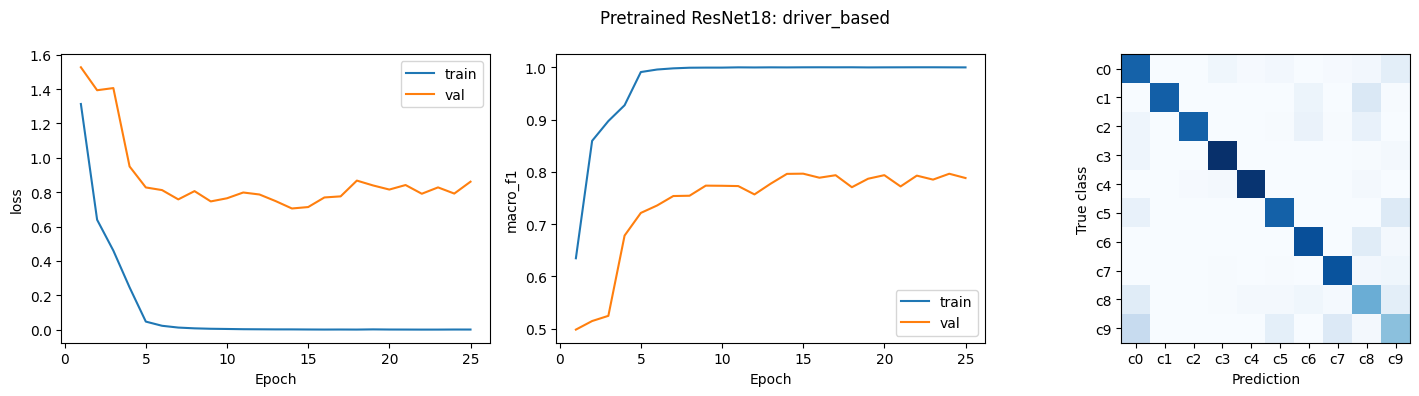

,run,accuracy,macro_f1,loss,train_macro_f1,f1_gap,model
0,driver_on,0.801554,0.796366,0.713476,1.000000,0.203634,pretrained_resnet18
1,driver_on,0.785457,0.778385,0.820202,0.993935,0.215550,scratch_cnn
2,driver_off,0.695532,0.685232,0.884831,0.994975,0.309743,scratch_cnn
3,random_on,0.989001,0.988811,0.049611,0.995371,0.006560,scratch_cnn
4,driver_on,0.802109,0.800785,1.062932,0.998990,0.198205,residual_cnn
5,random_on,0.994055,0.993885,0.026766,0.998861,0.004976,residual_cnn


In [22]:
resnet_summary = []
for protocol, folder in resnet_runs.items():
    network = make_resnet18()
    network.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
    scores, report, matrix, predictions = epoch(network, resnet_loader(splits[protocol]["val"]))
    train_scores, _, _, _ = epoch(network, resnet_loader(splits[protocol]["train"]))
    report.to_csv(folder / "validation_classes.csv", index=False)
    (folder / "validation_metrics.json").write_text(json.dumps(scores, indent=2))
    output = splits[protocol]["val"][["img", "subject", "classname"]].copy()
    output.columns = ["image_id", "subject", "true_class"]
    output["true_label"] = output.true_class.str[1:].astype(int)
    output["predicted_label"] = predictions
    output.to_csv(folder / "validation_predictions.csv", index=False)
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(folder / "validation_confusion.csv")
    resnet_summary.append(dict(run="driver_on" if protocol == "driver_based" else "random_on",
                               **scores, train_macro_f1=train_scores["macro_f1"],
                               f1_gap=train_scores["macro_f1"] - scores["macro_f1"]))
    if protocol == "driver_based":
        rows = []
        for subject, group in output.groupby("subject"):
            values, _, _ = metrics(group.true_label.to_numpy(), group.predicted_label.to_numpy())
            rows.append(dict(subject=subject, images=len(group), **values))
        pd.DataFrame(rows).to_csv(folder / "unseen_drivers.csv", index=False)
        display(pd.DataFrame(rows))
    history = pd.read_csv(folder / "history.csv")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes[:2], ["loss", "macro_f1"]):
        for part in ["train", "val"]:
            ax.plot(history.epoch, history[f"{part}_{metric}"], label=part)
        ax.set(xlabel="Epoch", ylabel=metric)
        ax.legend()
    axes[2].imshow(matrix, cmap="Blues")
    axes[2].set(xticks=range(10), yticks=range(10), xticklabels=CLASSES,
                yticklabels=CLASSES, xlabel="Prediction", ylabel="True class")
    fig.suptitle(f"Pretrained ResNet18: {protocol}")
    fig.tight_layout()
    fig.savefig(folder / "curves_confusion.png")
    plt.show()
resnet_summary = pd.DataFrame(resnet_summary)
resnet_summary.to_csv(root / "results" / "pretrained_resnet18" / "comparison.csv", index=False)
comparisons = [resnet_summary.assign(model="pretrained_resnet18")]
for model_name in ["scratch_cnn", "residual_cnn"]:
    path = root / "results" / model_name / "comparison.csv"
    if path.exists():
        comparisons.append(pd.read_csv(path).assign(model=model_name))
display(pd.concat(comparisons, ignore_index=True))

## Pretrained VGG16

In [54]:
from torchvision.models import vgg16, VGG16_Weights

VGG_WEIGHTS = VGG16_Weights.IMAGENET1K_V1

def make_vgg16(pretrained=False):
    network = vgg16(weights=VGG_WEIGHTS if pretrained else None)
    network.classifier[6] = nn.Linear(4096, 10)
    return network.to(DEVICE)

## Shared transfer-learning trainer

In [55]:
def train_transfer_model(protocol, model_name, factory, weights, head_name,
                         backbone_lr=1e-5, classifier_lr=1e-4,
                         data_loader=None, preprocessing=None):
    folder = root / "results" / model_name / protocol
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / "complete.json").exists():
        print("Reusing completed transfer-learning run:", protocol)
        return folder
    if (folder / "best.pt").exists():
        raise RuntimeError("Incomplete transfer-learning run. Use a new results folder for a fresh run.")
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    network = factory(pretrained=True)
    data_loader = data_loader or resnet_loader
    train_batches = data_loader(splits[protocol]["train"], training=True)
    val_batches = data_loader(splits[protocol]["val"])
    config = dict(architecture=model_name, weights=str(weights),
                  protocol=protocol, seed=SEED, hardware=HARDWARE, batch_size=BATCH_SIZE,
                  head_epochs=3, head_lr=.001, backbone_lr=backbone_lr, finetune_head_lr=classifier_lr,
                  weight_decay=.0001, max_finetune_epochs=MAX_EPOCHS, patience=PATIENCE,
                  selection="validation macro-F1", preprocessing=preprocessing or str(resnet_preprocess),
                  augmentation="rotation 8 degrees, brightness/contrast 0.15, training only")
    head = getattr(network, head_name)
    # Keep frozen backbone BatchNorm statistics fixed during head training.
    def freeze_backbone_stats(module, inputs):
        for name, child in module.named_children():
            if name != head_name:
                child.eval()
    for parameter in network.parameters():
        parameter.requires_grad = False
    for parameter in head.parameters():
        parameter.requires_grad = True
    hook = network.register_forward_pre_hook(freeze_backbone_stats)
    optimizer = torch.optim.Adam(head.parameters(), lr=.001, weight_decay=.0001)
    history, best, stale = [], -1., 0
    start = time.perf_counter()
    for number in range(1, 3 + MAX_EPOCHS + 1):
        if number == 4:
            hook.remove()
            for parameter in network.parameters():
                parameter.requires_grad = True
            optimizer = torch.optim.Adam([
                {"params": [p for name, p in network.named_parameters() if not name.startswith(head_name + ".")], "lr": backbone_lr},
                {"params": head.parameters(), "lr": classifier_lr},
            ], weight_decay=.0001)
            stale = 0
        stage = "head" if number <= 3 else "fine_tune"
        train_scores, _, _, _ = epoch(network, train_batches, optimizer)
        val_scores, _, _, _ = epoch(network, val_batches)
        history.append(dict(epoch=number, stage=stage,
                            **{f"train_{k}": v for k, v in train_scores.items()},
                            **{f"val_{k}": v for k, v in val_scores.items()}))
        print(model_name, protocol, number, stage, "val F1:", round(val_scores["macro_f1"], 4), flush=True)
        if val_scores["macro_f1"] > best:
            best, stale = val_scores["macro_f1"], 0
            torch.save(network.state_dict(), folder / "best.pt")
            config.update(best_epoch=number, best_stage=stage)
        else:
            stale += 1
        config["hours"] = (time.perf_counter() - start) / 3600
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
        (folder / "config.json").write_text(json.dumps(config, indent=2))
        if stage == "fine_tune" and stale >= PATIENCE:
            break
    (folder / "complete.json").write_text(json.dumps({"epochs": number}))
    return folder

## VGG16 driver-based experiment

In [25]:
# Reuse the ImageNet loader: VGG16 V1 and ResNet18 V1 use the same transforms.
vgg_runs = {"driver_based": train_transfer_model(
    "driver_based", "pretrained_vgg16", make_vgg16, VGG_WEIGHTS, "classifier")}

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\Obada/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [00:27<00:00, 20.2MB/s] 


pretrained_vgg16 driver_based 1 head val F1: 0.6444
pretrained_vgg16 driver_based 2 head val F1: 0.5689
pretrained_vgg16 driver_based 3 head val F1: 0.6348
pretrained_vgg16 driver_based 4 fine_tune val F1: 0.7268
pretrained_vgg16 driver_based 5 fine_tune val F1: 0.6816
pretrained_vgg16 driver_based 6 fine_tune val F1: 0.7416
pretrained_vgg16 driver_based 7 fine_tune val F1: 0.6826
pretrained_vgg16 driver_based 8 fine_tune val F1: 0.7183
pretrained_vgg16 driver_based 9 fine_tune val F1: 0.7561
pretrained_vgg16 driver_based 10 fine_tune val F1: 0.7167
pretrained_vgg16 driver_based 11 fine_tune val F1: 0.7172
pretrained_vgg16 driver_based 12 fine_tune val F1: 0.7792
pretrained_vgg16 driver_based 13 fine_tune val F1: 0.7624
pretrained_vgg16 driver_based 14 fine_tune val F1: 0.7819
pretrained_vgg16 driver_based 15 fine_tune val F1: 0.7161
pretrained_vgg16 driver_based 16 fine_tune val F1: 0.7195
pretrained_vgg16 driver_based 17 fine_tune val F1: 0.7735
pretrained_vgg16 driver_based 18 fine_

## Shared transfer-learning evaluation

In [56]:
def evaluate_transfer_model(model_runs, factory, model_name):
    transfer_summary = []
    for protocol, folder in model_runs.items():
        network = factory()
        network.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
        scores, report, matrix, predictions = epoch(network, resnet_loader(splits[protocol]["val"]))
        train_scores, _, _, _ = epoch(network, resnet_loader(splits[protocol]["train"]))
        report.to_csv(folder / "validation_classes.csv", index=False)
        (folder / "validation_metrics.json").write_text(json.dumps(scores, indent=2))
        output = splits[protocol]["val"][["img", "subject", "classname"]].copy()
        output.columns = ["image_id", "subject", "true_class"]
        output["true_label"] = output.true_class.str[1:].astype(int)
        output["predicted_label"] = predictions
        output.to_csv(folder / "validation_predictions.csv", index=False)
        pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(folder / "validation_confusion.csv")
        transfer_summary.append(dict(run="driver_on" if protocol == "driver_based" else "random_on",
                                   **scores, train_macro_f1=train_scores["macro_f1"],
                                   f1_gap=train_scores["macro_f1"] - scores["macro_f1"]))
        if protocol == "driver_based":
            rows = []
            for subject, group in output.groupby("subject"):
                values, _, _ = metrics(group.true_label.to_numpy(), group.predicted_label.to_numpy())
                rows.append(dict(subject=subject, images=len(group), **values))
            pd.DataFrame(rows).to_csv(folder / "unseen_drivers.csv", index=False)
            display(pd.DataFrame(rows))
        history = pd.read_csv(folder / "history.csv")
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for ax, metric in zip(axes[:2], ["loss", "macro_f1"]):
            for part in ["train", "val"]:
                ax.plot(history.epoch, history[f"{part}_{metric}"], label=part)
            ax.set(xlabel="Epoch", ylabel=metric)
            ax.legend()
        axes[2].imshow(matrix, cmap="Blues")
        axes[2].set(xticks=range(10), yticks=range(10), xticklabels=CLASSES,
                    yticklabels=CLASSES, xlabel="Prediction", ylabel="True class")
        fig.suptitle(f"{model_name}: {protocol}")
        fig.tight_layout()
        fig.savefig(folder / "curves_confusion.png")
        plt.show()
    transfer_summary = pd.DataFrame(transfer_summary)
    transfer_summary.to_csv(root / "results" / model_name / "comparison.csv", index=False)
    return transfer_summary

## VGG16 validation and comparison

,subject,images,accuracy,macro_f1
0,p014,876,0.678082,0.633374
1,p016,1078,0.848794,0.839674
2,p047,835,0.859880,0.833714
3,p075,814,0.878378,0.863489


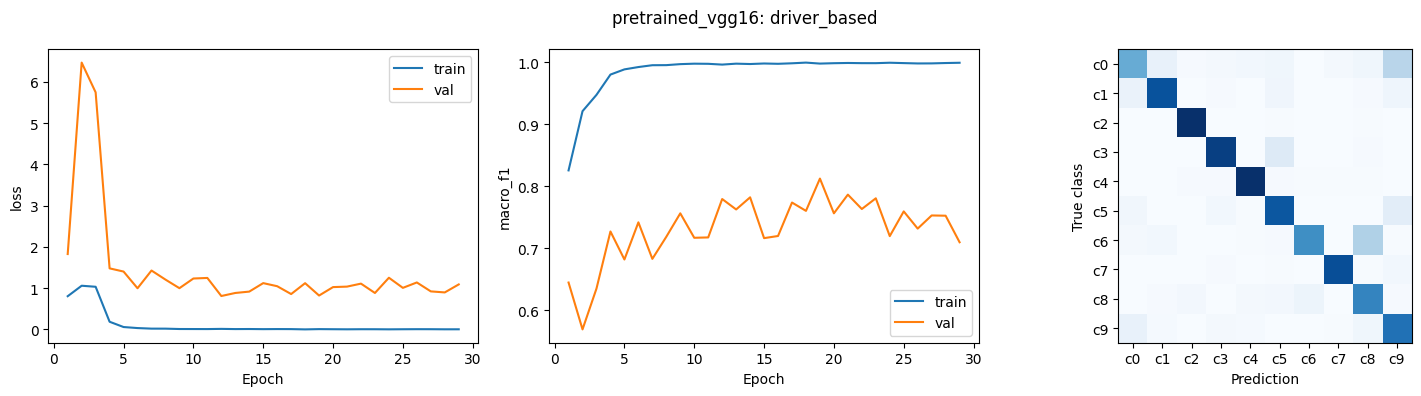

,run,accuracy,macro_f1,loss,train_macro_f1,f1_gap,model
0,driver_on,0.816542,0.812178,0.822438,0.999930,0.187753,pretrained_vgg16
1,driver_on,0.785457,0.778385,0.820202,0.993935,0.215550,scratch_cnn
2,driver_off,0.695532,0.685232,0.884831,0.994975,0.309743,scratch_cnn
3,random_on,0.989001,0.988811,0.049611,0.995371,0.006560,scratch_cnn
4,driver_on,0.802109,0.800785,1.062932,0.998990,0.198205,residual_cnn
5,random_on,0.994055,0.993885,0.026766,0.998861,0.004976,residual_cnn
6,driver_on,0.801554,0.796366,0.713476,1.000000,0.203634,pretrained_resnet18


In [27]:
vgg_summary = evaluate_transfer_model(vgg_runs, make_vgg16, "pretrained_vgg16")
comparisons = [vgg_summary.assign(model="pretrained_vgg16")]
for model_name in ["scratch_cnn", "residual_cnn", "pretrained_resnet18"]:
    path = root / "results" / model_name / "comparison.csv"
    if path.exists():
        comparisons.append(pd.read_csv(path).assign(model=model_name))
display(pd.concat(comparisons, ignore_index=True))

## ResNet18 higher learning rates

In [42]:
resnet_high_lr_runs = {"driver_based": train_transfer_model(
    "driver_based", "pretrained_resnet18_high_lr", make_resnet18,
    RESNET_WEIGHTS, "fc", backbone_lr=1e-4, classifier_lr=1e-3)}

Reusing completed transfer-learning run: driver_based


## Learning-rate comparison

,subject,images,accuracy,macro_f1
0,p014,876,0.925799,0.900541
1,p016,1078,0.907236,0.897397
2,p047,835,0.914970,0.904091
3,p075,814,0.863636,0.851512


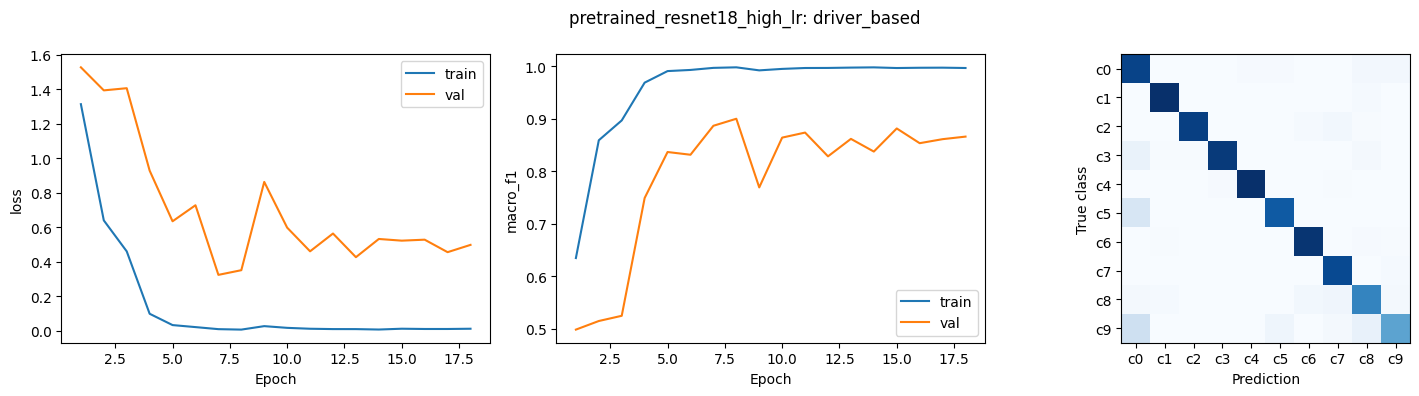

,run,accuracy,macro_f1,loss,train_macro_f1,f1_gap,setting
0,driver_on,0.801554,0.796366,0.713476,1.000000,0.203634,backbone 1e-5 / classifier 1e-4
1,driver_on,0.903691,0.900251,0.350720,0.997112,0.096861,backbone 1e-4 / classifier 1e-3


In [14]:
resnet_high_lr_summary = evaluate_transfer_model(
    resnet_high_lr_runs, make_resnet18, "pretrained_resnet18_high_lr")
low_lr_summary = pd.read_csv(root / "results" / "pretrained_resnet18" / "comparison.csv")
display(pd.concat([
    low_lr_summary.assign(setting="backbone 1e-5 / classifier 1e-4"),
    resnet_high_lr_summary.assign(setting="backbone 1e-4 / classifier 1e-3"),
], ignore_index=True))

## VGG16 higher learning rates

In [27]:
vgg_high_lr_runs = {"driver_based": train_transfer_model(
    "driver_based", "pretrained_vgg16_high_lr", make_vgg16,
    VGG_WEIGHTS, "classifier", backbone_lr=1e-4, classifier_lr=1e-3)}

pretrained_vgg16_high_lr driver_based 1 head val F1: 0.6444
pretrained_vgg16_high_lr driver_based 2 head val F1: 0.5689
pretrained_vgg16_high_lr driver_based 3 head val F1: 0.6348
pretrained_vgg16_high_lr driver_based 4 fine_tune val F1: 0.7668
pretrained_vgg16_high_lr driver_based 5 fine_tune val F1: 0.7687
pretrained_vgg16_high_lr driver_based 6 fine_tune val F1: 0.6907
pretrained_vgg16_high_lr driver_based 7 fine_tune val F1: 0.8529
pretrained_vgg16_high_lr driver_based 8 fine_tune val F1: 0.7946
pretrained_vgg16_high_lr driver_based 9 fine_tune val F1: 0.8431
pretrained_vgg16_high_lr driver_based 10 fine_tune val F1: 0.7756
pretrained_vgg16_high_lr driver_based 11 fine_tune val F1: 0.761
pretrained_vgg16_high_lr driver_based 12 fine_tune val F1: 0.7127
pretrained_vgg16_high_lr driver_based 13 fine_tune val F1: 0.816
pretrained_vgg16_high_lr driver_based 14 fine_tune val F1: 0.7644
pretrained_vgg16_high_lr driver_based 15 fine_tune val F1: 0.8578
pretrained_vgg16_high_lr driver_base

## VGG16 learning-rate comparison

,subject,images,accuracy,macro_f1
0,p014,876,0.923516,0.845219
1,p016,1078,0.886827,0.845783
2,p047,835,0.887425,0.877470
3,p075,814,0.891892,0.876328


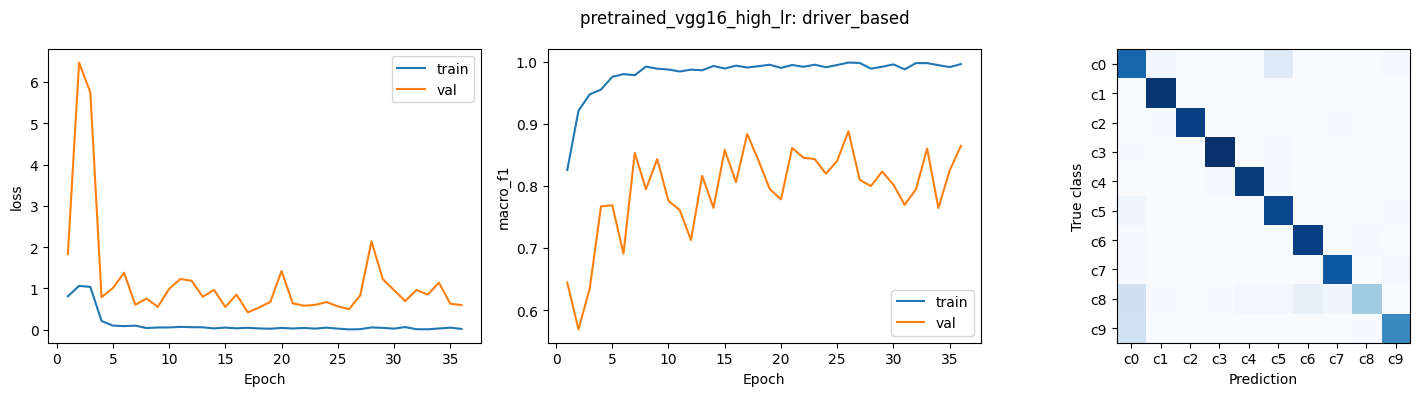

,run,accuracy,macro_f1,loss,train_macro_f1,f1_gap,setting
0,driver_on,0.816542,0.812178,0.822438,0.999930,0.187753,backbone 1e-5 / classifier 1e-4
1,driver_on,0.897030,0.887742,0.494449,0.999863,0.112120,backbone 1e-4 / classifier 1e-3


In [28]:
vgg_high_lr_summary = evaluate_transfer_model(
    vgg_high_lr_runs, make_vgg16, "pretrained_vgg16_high_lr")
vgg_low_lr_summary = pd.read_csv(root / "results" / "pretrained_vgg16" / "comparison.csv")
display(pd.concat([
    vgg_low_lr_summary.assign(setting="backbone 1e-5 / classifier 1e-4"),
    vgg_high_lr_summary.assign(setting="backbone 1e-4 / classifier 1e-3"),
], ignore_index=True))

## Two-resolution ResNet18 ensemble

In [57]:
from functools import partial

def resolution_loader(frame, training=False, size=(384, 512)):
    steps = [T.Resize(size)]  # (height, width); no crop.
    if training:
        steps += [T.RandomRotation(8), T.ColorJitter(brightness=.15, contrast=.15)]
    steps += [T.ToTensor(), T.Normalize((.485, .456, .406), (.229, .224, .225))]
    dataset = DriverDataset(frame, root / "imgs" / "train", T.Compose(steps))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=training, num_workers=0)

ensemble_sizes = {"512x384": (384, 512), "384x288": (288, 384)}

## Train ensemble members

In [44]:
ensemble_folders = {}
for resolution, size in ensemble_sizes.items():
    ensemble_folders[resolution] = train_transfer_model(
        "driver_based", f"ensemble_resnet18_{resolution}", make_resnet18,
        RESNET_WEIGHTS, "fc", backbone_lr=1e-4, classifier_lr=1e-3,
        data_loader=partial(resolution_loader, size=size),
        preprocessing=f"Full-frame resize HxW={size}; ImageNet normalization")

ensemble_resnet18_512x384 driver_based 1 head val F1: 0.4353
ensemble_resnet18_512x384 driver_based 2 head val F1: 0.4828
ensemble_resnet18_512x384 driver_based 3 head val F1: 0.486
ensemble_resnet18_512x384 driver_based 4 fine_tune val F1: 0.8655
ensemble_resnet18_512x384 driver_based 5 fine_tune val F1: 0.8547
ensemble_resnet18_512x384 driver_based 6 fine_tune val F1: 0.8996
ensemble_resnet18_512x384 driver_based 7 fine_tune val F1: 0.8888
ensemble_resnet18_512x384 driver_based 8 fine_tune val F1: 0.8961
ensemble_resnet18_512x384 driver_based 9 fine_tune val F1: 0.8641
ensemble_resnet18_512x384 driver_based 10 fine_tune val F1: 0.8682
ensemble_resnet18_512x384 driver_based 11 fine_tune val F1: 0.9187
ensemble_resnet18_512x384 driver_based 12 fine_tune val F1: 0.9271
ensemble_resnet18_512x384 driver_based 13 fine_tune val F1: 0.8901
ensemble_resnet18_512x384 driver_based 14 fine_tune val F1: 0.8664
ensemble_resnet18_512x384 driver_based 15 fine_tune val F1: 0.8818
ensemble_resnet18_51

## Validation and equal-weight soft voting

In [58]:
def predict_probabilities(network, batches):
    network.eval()
    probabilities = []
    with torch.no_grad():
        for images, _ in batches:
            probabilities.append(network(images.to(DEVICE)).softmax(dim=1).cpu())
    return torch.cat(probabilities).numpy()

ensemble_folder = root / "results" / "resnet18_resolution_ensemble"
ensemble_folder.mkdir(parents=True, exist_ok=True)
validation_frame = splits["driver_based"]["val"]
true_labels = validation_frame.classname.str[1:].astype(int).to_numpy()
member_probabilities, comparison = [], []
for resolution, size in ensemble_sizes.items():
    folder = ensemble_folders[resolution]
    network = make_resnet18()
    network.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
    probabilities = predict_probabilities(network, resolution_loader(validation_frame, size=size))
    member_probabilities.append(probabilities)
    np.save(folder / "validation_probabilities.npy", probabilities)
    scores, report, matrix = metrics(true_labels, probabilities.argmax(axis=1))
    report.to_csv(folder / "validation_classes.csv", index=False)
    (folder / "validation_metrics.json").write_text(json.dumps(scores, indent=2))
    comparison.append(dict(model=resolution, **scores))
    del network

# Identical image order and class order for both members.
soft_vote = np.mean(member_probabilities, axis=0)
scores, report, matrix = metrics(true_labels, soft_vote.argmax(axis=1))
comparison.append(dict(model="equal_soft_vote", **scores))
report.to_csv(ensemble_folder / "validation_classes.csv", index=False)
pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(ensemble_folder / "validation_confusion.csv")
np.save(ensemble_folder / "validation_probabilities.npy", soft_vote)
output = validation_frame[["img", "subject", "classname"]].copy()
output.columns = ["image_id", "subject", "true_class"]
output["true_label"] = true_labels
output["predicted_label"] = soft_vote.argmax(axis=1)
output.to_csv(ensemble_folder / "validation_predictions.csv", index=False)
(ensemble_folder / "validation_metrics.json").write_text(json.dumps(scores, indent=2))
configs = [json.loads((folder / "config.json").read_text()) for folder in ensemble_folders.values()]
(ensemble_folder / "config.json").write_text(json.dumps(dict(
    protocol="driver_based", voting="mean of probabilities", weights=[.5, .5],
    class_order=CLASSES, members={k: str(v) for k, v in ensemble_folders.items()},
    hardware=HARDWARE, total_training_hours=sum(c["hours"] for c in configs)), indent=2))
comparison = pd.DataFrame(comparison)
comparison.to_csv(ensemble_folder / "comparison.csv", index=False)
display(comparison)
rows = []
for subject, group in output.groupby("subject"):
    values, _, _ = metrics(group.true_label.to_numpy(), group.predicted_label.to_numpy())
    rows.append(dict(subject=subject, images=len(group), **values))
pd.DataFrame(rows).to_csv(ensemble_folder / "unseen_drivers.csv", index=False)
display(pd.DataFrame(rows))

,model,accuracy,macro_f1
0,512x384,0.938107,0.932456
1,384x288,0.920622,0.915882
2,equal_soft_vote,0.954482,0.951108


,subject,images,accuracy,macro_f1
0,p014,876,0.950913,0.916775
1,p016,1078,0.959184,0.955705
2,p047,835,0.955689,0.953793
3,p075,814,0.950860,0.950438


## Final test evaluation ? run after freezing all model choices

In [59]:
def test_once(folder, frame, get_probabilities):
    metrics_file = folder / "test_metrics.json"
    probabilities_file = folder / "test_probabilities.npy"
    if metrics_file.exists() and probabilities_file.exists():
        return json.loads(metrics_file.read_text()), np.load(probabilities_file)
    marker = folder / "test_started.txt"
    if marker.exists() or metrics_file.exists():
        raise RuntimeError(f"Incomplete previous test execution: {folder}. Inspect it before any rerun.")
    folder.mkdir(parents=True, exist_ok=True)
    marker.write_text("Final test started; do not rerun to select models.")
    probabilities = get_probabilities()
    truth = frame.classname.str[1:].astype(int).to_numpy()
    predicted = probabilities.argmax(axis=1)
    scores, report, matrix = metrics(truth, predicted)
    report.to_csv(folder / "test_classes.csv", index=False)
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(folder / "test_confusion.csv")
    predictions = frame[["img", "subject", "classname"]].copy()
    predictions.columns = ["image_id", "subject", "true_class"]
    predictions["true_label"] = truth
    predictions["predicted_label"] = predicted
    predictions.to_csv(folder / "test_predictions.csv", index=False)
    np.save(probabilities_file, probabilities)
    metrics_file.write_text(json.dumps(scores, indent=2))
    return scores, probabilities


def checkpoint_probabilities(folder, factory, batches):
    network = factory()
    network.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
    return predict_probabilities(network, batches)

## Test results for all saved models

In [60]:
test_jobs = []
for model_name, factory in [("scratch_cnn", lambda: DriverCNN().to(DEVICE)),
                            ("residual_cnn", lambda: ResidualDriverCNN().to(DEVICE))]:
    for folder in sorted((root / "results" / model_name).glob("*/best.pt")):
        folder = folder.parent
        config = json.loads((folder / "config.json").read_text())
        test_jobs.append((model_name, folder, config["protocol"], factory, loader))

for model_name, factory in [
    ("pretrained_resnet18", make_resnet18),
    ("pretrained_resnet18_high_lr", make_resnet18),
    ("pretrained_vgg16", make_vgg16),
    ("pretrained_vgg16_high_lr", make_vgg16),
]:
    folder = root / "results" / model_name / "driver_based"
    if (folder / "best.pt").exists():
        test_jobs.append((model_name, folder, "driver_based", factory, resnet_loader))

for resolution, size in ensemble_sizes.items():
    folder = root / "results" / f"ensemble_resnet18_{resolution}" / "driver_based"
    if (folder / "best.pt").exists():
        test_jobs.append((f"resnet18_{resolution}", folder, "driver_based", make_resnet18,
                          partial(resolution_loader, size=size)))

# Each run must be frozen before executing this cell. Test scores are for reporting only.
test_rows, ensemble_test_probabilities = [], {}
for model_name, folder, protocol, factory, make_loader in test_jobs:
    frame = splits[protocol]["test"]
    print("Test:", model_name, folder.name, flush=True)
    scores, probabilities = test_once(
        folder, frame,
        lambda: checkpoint_probabilities(folder, factory, make_loader(frame)))
    test_rows.append(dict(model=model_name, run=folder.name, protocol=protocol, **scores))
    if model_name.startswith("resnet18_"):
        ensemble_test_probabilities[model_name] = probabilities

if len(ensemble_test_probabilities) == 2:
    folder = root / "results" / "resnet18_resolution_ensemble"
    scores, _ = test_once(folder, splits["driver_based"]["test"],
                         lambda: np.mean(list(ensemble_test_probabilities.values()), axis=0))
    test_rows.append(dict(model="resnet18_soft_vote", run="equal_weights",
                          protocol="driver_based", **scores))

test_results = pd.DataFrame(test_rows)
test_results.to_csv(root / "results" / "final_test_comparison.csv", index=False)
display(test_results.style.format({"accuracy": "{:.2%}", "macro_f1": "{:.2%}"}))

Test: scratch_cnn driver_based_aug_False
Test: scratch_cnn driver_based_aug_True
Test: scratch_cnn random_aug_True
Test: residual_cnn driver_based_aug_True
Test: residual_cnn random_aug_True
Test: pretrained_resnet18 driver_based
Test: pretrained_resnet18_high_lr driver_based
Test: pretrained_vgg16 driver_based
Test: pretrained_vgg16_high_lr driver_based
Test: resnet18_512x384 driver_based
Test: resnet18_384x288 driver_based


,model,run,protocol,accuracy,macro_f1
0,scratch_cnn,driver_based_aug_False,driver_based,61.31%,61.27%
1,scratch_cnn,driver_based_aug_True,driver_based,68.76%,69.34%
2,scratch_cnn,random_aug_True,random,98.75%,98.72%
3,residual_cnn,driver_based_aug_True,driver_based,67.14%,67.52%
4,residual_cnn,random_aug_True,random,99.23%,99.21%
5,pretrained_resnet18,driver_based,driver_based,78.08%,77.75%
6,pretrained_resnet18_high_lr,driver_based,driver_based,84.33%,83.63%
7,pretrained_vgg16,driver_based,driver_based,80.25%,80.77%
8,pretrained_vgg16_high_lr,driver_based,driver_based,86.27%,85.29%
9,resnet18_512x384,driver_based,driver_based,89.74%,89.66%
